# Módulo 45: Modelado de datos

Autor: Juliho Castillo Colmenares

> Lección complementaria del ejercicio de este módulo: [enunciado](m45-modelado-de-datos-guia.ipynb) y [solución](m45-modelado-de-datos-solucion.ipynb). No es una tarea entregada del programa.

En el Módulo 44 dejamos limpias cinco tablas: las ventas y cuatro catálogos. Por separado no responden preguntas como "¿cuánto vendió cada categoría en Canadá?". Para eso hay que **relacionarlas**, y la forma de hacerlo determina si los totales salen bien, si los filtros llegan a donde esperamos y si las consultas son sencillas. En esta lección diseñamos ese modelo con **DuckDB** y SQL; cada concepto de una herramienta de BI (relaciones, cardinalidad, dirección del filtro, relaciones inactivas) tiene su equivalente en una consulta.

1. Tablas de hechos y dimensiones
2. Esquema estrella y copo de nieve
3. Claves y cardinalidad
4. Dirección del filtro
5. Relaciones inactivas y dimensiones con varios roles
6. Las medidas viven en `ventas.py`
7. Errores frecuentes
8. Ejercicio

In [1]:
import sys
from pathlib import Path

import duckdb
import pandas as pd
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "png"
pio.defaults.default_width = 900
pio.defaults.default_height = 450

sys.path.insert(0, str(Path("../practica-ventas").resolve()))
import ventas as practica

DATOS = Path("../practica-ventas/datos-ventas")

con = practica.conectar()


def miles(n):
    # 1499000 -> "1 499 000"
    return f"{int(n):,}".replace(",", " ")


con.sql("SHOW TABLES").df()

,name
0,calendario
1,clientes
2,paises
3,productos
4,tiendas
5,ventas
6,ventas_detalle


`conectar()` abre una base DuckDB en memoria cuyas tablas leen los archivos Parquet de `../practica-ventas/datos-modelo/`. No carga 1,5 millones de filas en pandas: DuckDB las lee del disco solo cuando una consulta las necesita, y `.df()` devuelve únicamente el resultado.

## 1. Tablas de hechos y dimensiones

Un modelo analítico distingue dos tipos de tabla:

| Tipo | Qué guarda | Forma | En los datos de ventas |
| --- | --- | --- | --- |
| **Hechos** (*fact*) | Eventos medibles: cada venta, cada visita | Muchas filas, columnas numéricas y claves | `ventas`: una fila por línea de venta, con `cantidad`, `precio`, `importe` y cuatro claves |
| **Dimensión** (*dimension*) | Descripciones de las entidades | Pocas filas, columnas de texto | `paises`, `clientes`, `productos`, `tiendas` y `calendario` |

Las dimensiones responden al "por qué" de un análisis (por país, por categoría, por tienda) y la tabla de hechos aporta el "cuánto". En un gráfico, las columnas de las dimensiones van a los ejes y a los filtros; las columnas numéricas de los hechos se agregan.

In [2]:
def describir(tabla):
    columnas = con.execute(f"DESCRIBE {tabla}").df()
    filas = con.execute(f"SELECT count(*) FROM {tabla}").fetchone()[0]
    tipos = ", ".join(f"{c} ({t})" for c, t in zip(columnas["column_name"], columnas["column_type"]))
    return {"tabla": tabla, "filas": filas, "columnas": tipos}


pd.set_option("display.max_colwidth", 200)
pd.DataFrame([describir(t) for t in ["ventas", "paises", "clientes", "productos", "tiendas", "calendario"]])

,tabla,filas,columnas
0,ventas,1499000,"fecha (DATE), id_pais (TINYINT), id_tienda (SMALLINT), id_cliente (SMALLINT), id_producto (SMALLINT), cantidad (SMALLINT), precio (SMALLINT), importe (BIGINT)"
1,paises,10,"id_pais (BIGINT), pais (VARCHAR)"
2,clientes,950,"id_cliente (BIGINT), nombre (VARCHAR), apellido (VARCHAR), correo (VARCHAR), telefono (VARCHAR)"
3,productos,1000,"id_producto (BIGINT), categoria (VARCHAR), subcategoria (VARCHAR), producto (VARCHAR)"
4,tiendas,200,"id_tienda (BIGINT), tienda (VARCHAR), direccion (VARCHAR), formato (VARCHAR)"
5,calendario,1096,"anio (INTEGER), trimestre (INTEGER), mes (INTEGER), nombre_mes (VARCHAR), anio_mes (VARCHAR), fecha (DATE)"


La diferencia de tamaño es la firma del modelo: una tabla de hechos con más de un millón de filas y dimensiones de diez a mil filas.

**Granularidad.** Antes de relacionar nada hay que saber qué representa una fila de la tabla de hechos: su **granularidad** (*grain*). Aquí cada fila es una línea de venta: un producto vendido a un cliente en una tienda y una fecha. ¿Basta esa combinación para identificar una fila?

In [3]:
filas, combinaciones = con.execute(
    "SELECT count(*), count(DISTINCT (fecha, id_tienda, id_cliente, id_producto)) FROM ventas"
).fetchone()
print(f"Filas: {miles(filas)} | combinaciones distintas de fecha, tienda, cliente y producto: {miles(combinaciones)}")

Filas: 1 499 000 | combinaciones distintas de fecha, tienda, cliente y producto: 1 498 964


No: unas pocas combinaciones se repiten, porque el mismo cliente pudo comprar el mismo producto dos veces el mismo día en la misma tienda. La tabla de hechos no tiene clave natural (el número de transacción `ID_T` se descartó en el Módulo 44 porque cada archivo empezaba en 1), y no la necesita: las relaciones van **de las dimensiones a los hechos**, y la clave que importa es la de cada dimensión.

**Medidas aditivas.** Una columna de hechos es **aditiva** si su suma tiene sentido por cualquier dimensión. `importe` y `cantidad` lo son: la suma de las ventas por país da el total. `precio` no lo es: sumar precios no significa nada, y promediar promedios tampoco da el promedio global.

In [4]:
por_pais = con.sql(
    "SELECT id_pais, sum(importe) AS ventas, avg(precio) AS precio_medio FROM ventas GROUP BY id_pais"
).df()
total, precio_global = con.execute("SELECT sum(importe), avg(precio) FROM ventas").fetchone()

print("Suma de las ventas por país:", miles(por_pais["ventas"].sum()), "| total:", miles(total))
print(f"Promedio de los precios medios por país: {por_pais['precio_medio'].mean():.4f} | precio medio global: {precio_global:.4f}")

Suma de las ventas por país: 41 940 958 825 | total: 41 940 958 825
Promedio de los precios medios por país: 264.3519 | precio medio global: 264.4811


| Columna | Tipo de medida | Cómo se agrega |
| --- | --- | --- |
| `importe` | Aditiva | `sum` por cualquier dimensión |
| `cantidad` | Aditiva | `sum` por cualquier dimensión |
| `precio` | No aditiva | `avg` o `median` calculados sobre las filas, nunca sumados ni promediados por grupos |

## 2. Esquema estrella y copo de nieve

En un **esquema estrella** (*star schema*) la tabla de hechos está en el centro y cada dimensión se relaciona directamente con ella. Es el modelo de `ventas.py`:

```text
                 paises
                    │ 1
                    │
                    │ *
 clientes 1 ──── * ventas * ──── 1 productos
                    │ *
                    │
                    │ 1
                 tiendas
```

En un **copo de nieve** (*snowflake*) las dimensiones se normalizan en varias tablas encadenadas. Por ejemplo, separando las categorías de los productos:

```text
ventas * ── 1 productos * ── 1 subcategorias * ── 1 categorias
```

En `productos`, `categoria` y `subcategoria` vienen dentro de la tabla: es una dimensión plana. Cada subcategoría pertenece a una sola categoría, así que se puede normalizar sin perder información. Construyamos el copo de nieve en DuckDB para compararlo:

In [5]:
con.execute(
    "SELECT count(*), count(DISTINCT categoria), count(DISTINCT subcategoria) FROM productos"
).fetchone()

(1000, 3, 13)

In [6]:
con.execute("""
    CREATE OR REPLACE TABLE categorias AS
    SELECT row_number() OVER (ORDER BY categoria) AS id_categoria, categoria
    FROM (SELECT DISTINCT categoria FROM productos)
""")
con.execute("""
    CREATE OR REPLACE TABLE subcategorias AS
    SELECT row_number() OVER (ORDER BY s.subcategoria) AS id_subcategoria, s.subcategoria, c.id_categoria
    FROM (SELECT DISTINCT subcategoria, categoria FROM productos) s
    JOIN categorias c USING (categoria)
""")
con.execute("""
    CREATE OR REPLACE TABLE productos_copo AS
    SELECT p.id_producto, p.producto, s.id_subcategoria
    FROM productos p
    JOIN subcategorias s USING (subcategoria)
""")
for tabla in ["productos_copo", "subcategorias", "categorias"]:
    print(f"{tabla:15}", con.execute(f"SELECT count(*) FROM {tabla}").fetchone()[0], "filas")
con.sql("SELECT * FROM subcategorias ORDER BY id_categoria, id_subcategoria").df()

productos_copo  1000 filas
subcategorias   13 filas
categorias      3 filas


,id_subcategoria,subcategoria,id_categoria
0,5,Bookcases,1
1,6,Chairs,1
2,8,Furnishings,1
3,13,Tables,1
4,2,Appliances,2
5,3,Art,2
6,4,Binders,2
7,11,Storage,2
8,12,Supplies,2
9,1,Accessories,3


La misma pregunta, "ventas por categoría", necesita una unión en la estrella y tres en el copo de nieve:

In [7]:
estrella = con.sql("""
    SELECT p.categoria, CAST(sum(v.importe) AS BIGINT) AS ventas
    FROM ventas v
    JOIN productos p USING (id_producto)
    GROUP BY p.categoria
    ORDER BY ventas DESC
""").df()

copo = con.sql("""
    SELECT c.categoria, CAST(sum(v.importe) AS BIGINT) AS ventas
    FROM ventas v
    JOIN productos_copo p USING (id_producto)
    JOIN subcategorias s USING (id_subcategoria)
    JOIN categorias c USING (id_categoria)
    GROUP BY c.categoria
    ORDER BY ventas DESC
""").df()

pd.testing.assert_frame_equal(estrella, copo)
estrella

,categoria,ventas
0,Technology,17636783425
1,Furniture,15750407426
2,Office Supplies,8553767974


El resultado es idéntico; lo que cambia es el costo de llegar a él:

| | Estrella | Copo de nieve |
| --- | --- | --- |
| Tablas de producto | 1 | 3 (`productos_copo`, `subcategorias`, `categorias`) |
| Uniones para filtrar los hechos por categoría | 1 | 3 |
| Repetición de texto | `categoria` repite 3 valores en 1000 filas | Mínima |
| Facilidad para quien escribe consultas o arma un dashboard | Alta | Menor: hay que conocer la cadena de claves |
| Recomendación en BI | Preferido | Aplanar al preparar los datos cuando se pueda |

En BI se prefiere la estrella porque las dimensiones son pequeñas: repetir "Furniture" en cientos de filas de una tabla de mil cuesta casi nada, y a cambio cada filtro llega a los hechos en un solo salto, las consultas son más cortas y hay menos formas de equivocarse al unir. El copo de nieve tiene sentido en bases transaccionales, donde evitar la repetición protege contra inconsistencias al actualizar.

Para aplanar un copo de nieve basta con unir la cadena una vez, al preparar los datos, y guardar el resultado como la dimensión:

In [8]:
plana = con.sql("""
    SELECT p.id_producto, c.categoria, s.subcategoria, p.producto
    FROM productos_copo p
    JOIN subcategorias s USING (id_subcategoria)
    JOIN categorias c USING (id_categoria)
    ORDER BY p.id_producto
""").df()
pd.testing.assert_frame_equal(plana, con.sql("SELECT * FROM productos ORDER BY id_producto").df())
print("Aplanar el copo de nieve devuelve exactamente la dimensión productos.")

Aplanar el copo de nieve devuelve exactamente la dimensión productos.


## 3. Claves y cardinalidad

Una relación une una columna de una tabla con una columna de otra. En SQL no se "dibuja": es la condición de un `JOIN`. La **cardinalidad** describe cuántas filas de cada lado pueden coincidir:

| Cardinalidad | Significado | Ejemplo en los datos | Uso |
| --- | --- | --- | --- |
| **Uno a varios** (1:\*) | Cada valor aparece una vez en un lado y muchas en el otro | `paises.id_pais` → `ventas.id_pais` | La relación normal entre dimensión y hechos |
| **Uno a uno** (1:1) | Cada valor aparece una vez en ambos lados | `paises` y la tabla de códigos ISO de los mapas | Suele indicar que las dos tablas deberían ser una |
| **Varios a varios** (\*:\*) | Los valores se repiten en ambos lados | Un presupuesto por categoría y año frente a `productos` | Casos especiales; hay que agregar antes de unir |

La cardinalidad se mide comparando `count(*)` con `count(DISTINCT clave)` en cada lado: si coinciden, la clave es única en ese lado.

In [9]:
filas = []
for clave, dimension in practica.RELACIONES:
    n_dim, d_dim = con.execute(f"SELECT count(*), count(DISTINCT {clave}) FROM {dimension}").fetchone()
    n_hechos, d_hechos = con.execute(f"SELECT count(*), count(DISTINCT {clave}) FROM ventas").fetchone()
    filas.append({
        "clave": clave, "dimension": dimension,
        "filas_dim": n_dim, "distintas_dim": d_dim,
        "filas_ventas": n_hechos, "distintas_ventas": d_hechos,
        "lado_uno": "dimensión" if n_dim == d_dim else "ninguno",
    })
pd.DataFrame(filas)

,clave,dimension,filas_dim,distintas_dim,filas_ventas,distintas_ventas,lado_uno
0,id_pais,paises,10,10,1499000,10,dimensión
1,id_tienda,tiendas,200,200,1499000,200,dimensión
2,id_cliente,clientes,950,950,1499000,950,dimensión
3,id_producto,productos,1000,1000,1499000,1000,dimensión


En las cuatro dimensiones la clave es única, y en `ventas` se repite: son relaciones uno a varios. `practica.validar_modelo` hace esta comprobación y añade dos más: las **ventas huérfanas** (claves de los hechos que no existen en la dimensión, que con un `INNER JOIN` desaparecerían del total) y las **claves sin ventas** (filas de la dimensión que ningún hecho usa). Las dos se cuentan con `ANTI JOIN`, que devuelve las filas de la izquierda sin pareja a la derecha.

In [10]:
practica.validar_modelo(con)

,relacion,filas_dimension,claves_distintas,cardinalidad,ventas_huerfanas,claves_sin_ventas
0,paises[id_pais] -> ventas[id_pais],10,10,1:*,0,0
1,tiendas[id_tienda] -> ventas[id_tienda],200,200,1:*,0,0
2,clientes[id_cliente] -> ventas[id_cliente],950,950,1:*,0,0
3,productos[id_producto] -> ventas[id_producto],1000,1000,1:*,0,0


Las cuatro relaciones son 1:\*, sin huérfanas y sin claves sin uso: el modelo está sano.

También hay que mirar los **tipos**. En las dimensiones las claves son `BIGINT` y en `ventas` son enteros más pequeños (`TINYINT`, `SMALLINT`, elegidos para que el Parquet ocupe menos). Son de la misma familia y DuckDB los compara sin problema; el peligro real es mezclar texto y números (sección 7).

**Uno a uno.** Los códigos ISO que necesitan los mapas de Plotly están en el diccionario `practica.ISO3`. Como tabla, tiene un país por fila, igual que `paises`:

In [11]:
iso = pd.DataFrame(list(practica.ISO3.items()), columns=["pais", "iso3"])
con.register("iso", iso)
con.sql("""
    SELECT (SELECT count(*) FROM paises) AS filas_paises,
           (SELECT count(DISTINCT pais) FROM paises) AS distintos_paises,
           (SELECT count(*) FROM iso) AS filas_iso,
           (SELECT count(DISTINCT pais) FROM iso) AS distintos_iso,
           (SELECT count(*) FROM paises JOIN iso USING (pais)) AS parejas
""").df()

,filas_paises,distintos_paises,filas_iso,distintos_iso,parejas
0,10,10,10,10,10


Diez filas, diez valores distintos y diez parejas en ambos lados: una relación 1:1. Mantener dos tablas no aporta nada; lo natural es que `iso3` sea una columna más de la dimensión de países, que es lo que hace `practica.tabla_por_pais`.

**Varios a varios.** Supongamos (es una tabla **simulada**, no viene en los datos) que el área comercial fija un presupuesto anual por categoría. La categoría se repite en el presupuesto (una fila por año) y en `productos` (cientos de filas por categoría):

In [12]:
presupuesto = pd.DataFrame({
    "categoria": ["Technology", "Furniture", "Office Supplies"] * 3,
    "anio": [2019] * 3 + [2020] * 3 + [2021] * 3,
    "presupuesto": [6_000_000_000, 5_400_000_000, 2_900_000_000,
                    2_500_000_000, 2_200_000_000, 1_200_000_000,
                    9_500_000_000, 9_000_000_000, 4_600_000_000],
})
con.register("presupuesto", presupuesto)

ingenuo, real = con.execute("""
    SELECT (SELECT sum(b.presupuesto) FROM presupuesto b JOIN productos p USING (categoria)),
           (SELECT sum(presupuesto) FROM presupuesto)
""").fetchone()
print("Presupuesto total unido a productos:", miles(ingenuo))
print("Presupuesto total real:             ", miles(real))

Presupuesto total unido a productos: 15 587 100 000 000
Presupuesto total real:              43 300 000 000


Al unir por `categoria`, cada fila del presupuesto se repite tantas veces como productos tiene su categoría, y el total se multiplica. La forma correcta es **llevar los hechos a la granularidad del presupuesto** (categoría y año) y unir después, cuando la clave ya es única en ambos lados:

In [13]:
con.sql("""
    WITH ventas_cat AS (
        SELECT p.categoria, year(v.fecha) AS anio, CAST(sum(v.importe) AS BIGINT) AS ventas
        FROM ventas v
        JOIN productos p USING (id_producto)
        GROUP BY ALL
    )
    SELECT categoria, anio, ventas, presupuesto, round(ventas / presupuesto, 3) AS cumplimiento
    FROM ventas_cat
    JOIN presupuesto USING (categoria, anio)
    WHERE anio = 2021
    ORDER BY ventas DESC
""").df()

,categoria,anio,ventas,presupuesto,cumplimiento
0,Technology,2021,9836425209,9500000000,1.035
1,Furniture,2021,8750007775,9000000000,0.972
2,Office Supplies,2021,4752313446,4600000000,1.033


**Una dimensión con claves repetidas: el *fan-out*.** El caso más peligroso de varios a varios es el que nadie busca: una dimensión que *debería* tener la clave única y no la tiene. La hoja `t_store` de `catalogo.xlsx`, sin limpiar, tiene 204 filas para 200 tiendas, porque cuatro tiendas aparecen como `Open` y como `Closed` (Módulo 44). Si se usa como dimensión tal cual:

In [14]:
t_store = pd.read_excel(DATOS / "catalogo.xlsx", sheet_name="t_store", header=2)
con.register("t_store_crudo", t_store)
print(len(t_store), "filas,", t_store["ID_Store"].nunique(), "tiendas distintas")

filas_ok, total_ok = con.execute("SELECT count(*), sum(importe) FROM ventas").fetchone()
filas_mal, total_mal = con.execute("""
    SELECT count(*), sum(v.importe)
    FROM ventas v
    JOIN t_store_crudo t ON v.id_tienda = t.ID_Store
""").fetchone()
print(f"ventas sola:              {miles(filas_ok):>10} filas | {miles(total_ok):>15}")
print(f"ventas JOIN t_store cruda: {miles(filas_mal):>10} filas | {miles(total_mal):>15}")
print(f"diferencia:               {miles(filas_mal - filas_ok):>10} filas | {miles(total_mal - total_ok):>15}")
print(f"inflación del total: {total_mal / total_ok - 1:.2%}")

204 filas, 200 tiendas distintas
ventas sola:               1 499 000 filas |  41 940 958 825
ventas JOIN t_store cruda:  1 529 120 filas |  42 782 781 776
diferencia:                   30 120 filas |     841 822 951
inflación del total: 2.01%


Cada venta de una tienda repetida encuentra **dos** filas en la dimensión, y el `JOIN` la duplica. Las ventas que sobran son exactamente las de las cuatro tiendas repetidas:

In [15]:
con.sql("""
    SELECT id_tienda, count(*) AS filas, CAST(sum(importe) AS BIGINT) AS ventas
    FROM ventas
    WHERE id_tienda IN (SELECT ID_Store FROM t_store_crudo GROUP BY ID_Store HAVING count(*) > 1)
    GROUP BY id_tienda
    UNION ALL
    SELECT NULL, count(*), CAST(sum(importe) AS BIGINT)
    FROM ventas
    WHERE id_tienda IN (SELECT ID_Store FROM t_store_crudo GROUP BY ID_Store HAVING count(*) > 1)
    ORDER BY id_tienda NULLS LAST
""").df()

,id_tienda,filas,ventas
0,17,7415,213871636
1,167,7734,217145035
2,188,7480,203204884
3,197,7491,207601396
4,<NA>,30120,841822951


La suma de la última fila coincide con la diferencia de arriba. Nada falla: no hay error ni aviso, solo un total un 2 % más alto. Por eso la clave de cada dimensión se comprueba **antes** de relacionar, y se arregla en la preparación (quedarse con la fila `Open`), no cambiando la cardinalidad de la relación.

## 4. Dirección del filtro

En una herramienta de BI cada relación tiene una **dirección de filtro**. La habitual, **única**, va de la dimensión a los hechos: al elegir "CANADA" en un filtro de países, las ventas se reducen a las de Canadá. En SQL eso es un `JOIN` con un `WHERE` sobre la columna de la dimensión:

In [16]:
con.sql("""
    SELECT pr.categoria, CAST(sum(v.importe) AS BIGINT) AS ventas
    FROM ventas v
    JOIN paises pa USING (id_pais)
    JOIN productos pr USING (id_producto)
    WHERE pa.pais = 'CANADA'
    GROUP BY pr.categoria
    ORDER BY ventas DESC
""").df()

,categoria,ventas
0,Technology,2826299532
1,Furniture,2504580878
2,Office Supplies,1352643681


El filtro sobre `paises` viaja a `ventas` a través de la relación, y el resultado se agrupa por otra dimensión. Esta es la respuesta a "¿cuánto vendió cada categoría en Canadá?".

El filtro **en ambas direcciones** hace también el camino inverso: de los hechos a otra dimensión. "¿Qué productos se vendieron en Canadá en enero de 2019?" no pide sumar ventas, sino reducir la dimensión `productos` a los que tienen al menos una venta que cumpla el filtro. En SQL eso es un **semi-join**: `EXISTS`, o `SEMI JOIN` en DuckDB, que devuelve cada fila de la izquierda una sola vez si tiene alguna pareja a la derecha.

In [17]:
con_exists = con.execute("""
    SELECT count(*)
    FROM productos p
    WHERE EXISTS (
        SELECT 1
        FROM ventas v
        JOIN paises pa USING (id_pais)
        WHERE v.id_producto = p.id_producto
          AND pa.pais = 'CANADA'
          AND v.fecha BETWEEN DATE '2019-01-01' AND DATE '2019-01-31'
    )
""").fetchone()[0]

con_semi = con.execute("""
    SELECT count(*)
    FROM productos p
    SEMI JOIN (
        SELECT v.id_producto
        FROM ventas v
        JOIN paises pa USING (id_pais)
        WHERE pa.pais = 'CANADA' AND v.fecha BETWEEN DATE '2019-01-01' AND DATE '2019-01-31'
    ) USING (id_producto)
""").fetchone()[0]

total_productos = con.execute("SELECT count(*) FROM productos").fetchone()[0]
print(f"Productos vendidos en Canadá en enero de 2019: {con_exists} (EXISTS) = {con_semi} (SEMI JOIN) de {total_productos}")

Productos vendidos en Canadá en enero de 2019: 931 (EXISTS) = 931 (SEMI JOIN) de 1000


Es lo que haría un filtro de productos "que se encoge" para mostrar solo los que tienen ventas en la selección actual. Tiene costos que conviene conocer:

| Riesgo | Por qué ocurre |
| --- | --- |
| **Resultados inesperados** | La dimensión cambia según filtros sobre *otras* dimensiones: "cuántos productos hay" pasa a depender del país elegido |
| **Ambigüedad** | Con varias relaciones bidireccionales puede haber dos caminos entre dos tablas (de clientes a productos por las ventas, y de vuelta) |
| **Rendimiento** | Para reducir una dimensión de mil filas hay que recorrer la tabla de hechos |

Además, en estos datos casi no aporta información: en el periodo completo, cada país vendió todos los productos.

In [18]:
con.sql("""
    SELECT pa.pais, count(DISTINCT v.id_producto) AS productos_vendidos
    FROM ventas v
    JOIN paises pa USING (id_pais)
    GROUP BY pa.pais
    ORDER BY pa.pais
""").df().set_index("pais").T

pais,BRAZIL,CANADA,CHILE,COLOMBIA,FRANCE,MEXICO,PERU,PORTUGAL,SPAIN,US
productos_vendidos,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000


La recomendación es la misma que en BI: dejar el modelo con filtros de una sola dirección y escribir la pregunta inversa como una **medida explícita** cuando haga falta. Así "productos del catálogo" y "productos con ventas" son dos números distintos con nombres distintos, y nadie los confunde. Con `practica.filtro_sql` la medida acepta los mismos filtros que las demás:

In [19]:
def productos_con_ventas(con, **filtros):
    # Semi-join como medida: productos distintos con al menos una venta en la selección
    where, params = practica.filtro_sql(**filtros)
    return con.execute(f"SELECT count(DISTINCT id_producto) FROM ventas_detalle {where}", params).fetchone()[0]


print("Sin filtros:                        ", productos_con_ventas(con))
print("Canadá, enero de 2019:              ", productos_con_ventas(con, paises=["CANADA"], desde="2019-01-01", hasta="2019-01-31"))
print("Canadá, 1 de enero de 2019:         ", productos_con_ventas(con, paises=["CANADA"], desde="2019-01-01", hasta="2019-01-01"))

Sin filtros:                         1000
Canadá, enero de 2019:               931
Canadá, 1 de enero de 2019:          88


## 5. Relaciones inactivas y dimensiones con varios roles

Entre dos tablas, una herramienta de BI solo deja **una relación activa**; las demás quedan inactivas y se activan dentro de una medida (`USERELATIONSHIP`). El caso típico son dos fechas: la del pedido y la de entrega, ambas relacionadas con el mismo calendario.

Nuestros datos solo tienen una fecha. Para ver la idea vamos a **simular** una fecha de entrega, entre 1 y 5 días después del pedido, calculada de forma determinista a partir de las claves. Es un dato inventado para la demostración, no parte del extracto:

In [20]:
con.execute("""
    CREATE OR REPLACE VIEW ventas_con_entrega AS
    SELECT *, fecha + CAST(1 + (id_cliente + id_producto) % 5 AS INTEGER) AS fecha_entrega
    FROM ventas
""")
con.sql("SELECT fecha, fecha_entrega, importe FROM ventas_con_entrega LIMIT 3").df()

,fecha,fecha_entrega,importe
0,2019-01-01,2019-01-02,23296
1,2019-01-01,2019-01-05,32660
2,2019-01-01,2019-01-02,3666


En SQL no hay relaciones "activas" o "inactivas": **es cada consulta la que elige por qué columna unir**. Unir el calendario por `fecha` responde "¿cuánto se pidió cada mes?"; unirlo por `fecha_entrega`, "¿cuánto se entregó cada mes?". El calendario no se duplica: la misma tabla cumple dos **roles**.

In [21]:
por_mes = con.sql("""
    WITH por_pedido AS (
        SELECT c.anio_mes, CAST(sum(v.importe) AS BIGINT) AS ventas_por_pedido
        FROM ventas_con_entrega v
        JOIN calendario c ON c.fecha = v.fecha
        GROUP BY c.anio_mes
    ),
    por_entrega AS (
        SELECT c.anio_mes, CAST(sum(v.importe) AS BIGINT) AS ventas_por_entrega
        FROM ventas_con_entrega v
        JOIN calendario c ON c.fecha = v.fecha_entrega
        GROUP BY c.anio_mes
    )
    SELECT * FROM por_pedido FULL JOIN por_entrega USING (anio_mes)
    ORDER BY anio_mes
""").df()
pd.concat([por_mes.head(3), por_mes.tail(2)])

,anio_mes,ventas_por_pedido,ventas_por_entrega
0,2019-01,1055072666,954220050
1,2019-02,952801751,954183407
2,2019-03,1931341497,1852042480
34,2021-11,1868959841,1875813632
35,2021-12,1928765134,1922561393


Cada mes, por fecha de entrega, gana las ventas pedidas en los últimos días del mes anterior y pierde las de sus propios últimos días. Enero de 2019 sale más bajo por entrega porque no hay pedidos de diciembre de 2018 que compensen. Y las dos columnas no suman lo mismo en total:

In [22]:
total_pedido = por_mes["ventas_por_pedido"].sum()
total_entrega = por_mes["ventas_por_entrega"].sum()
print("Total por fecha de pedido: ", miles(total_pedido))
print("Total por fecha de entrega:", miles(total_entrega))

fuera, importe_fuera, ultimo_dia = con.execute("""
    SELECT count(*), sum(v.importe), (SELECT max(fecha) FROM calendario)
    FROM ventas_con_entrega v
    LEFT JOIN calendario c ON c.fecha = v.fecha_entrega
    WHERE c.fecha IS NULL
""").fetchone()
print(f"Ventas entregadas después del {ultimo_dia}, fuera del calendario: {miles(fuera)} ({miles(importe_fuera)})")

Total por fecha de pedido:  41 940 958 825
Total por fecha de entrega: 41 751 131 670
Ventas entregadas después del 2021-12-31, fuera del calendario: 5 701 (189 827 155)


Las ventas de finales de diciembre de 2021 se entregan en 2022, y el calendario termina el 31 de diciembre de 2021. Con `INNER JOIN` esas ventas desaparecen del total por fecha de entrega sin ningún aviso; con `LEFT JOIN` aparecerían con mes vacío. Es el mismo problema que en una herramienta de BI: la dimensión de fechas debe cubrir **todas** las fechas de todos sus roles.

Cuando una consulta necesita los dos roles a la vez, se une el calendario dos veces con alias distintos. Por ejemplo, cuántas ventas se pidieron en un mes y se entregaron en otro:

In [23]:
con.sql("""
    SELECT count(*) AS ventas,
           count(*) FILTER (WHERE c_entrega.anio_mes IS DISTINCT FROM c_pedido.anio_mes) AS cambian_de_mes
    FROM ventas_con_entrega v
    JOIN calendario c_pedido ON c_pedido.fecha = v.fecha
    LEFT JOIN calendario c_entrega ON c_entrega.fecha = v.fecha_entrega
""").df()

,ventas,cambian_de_mes
0,1499000,147355


`IS DISTINCT FROM` trata el mes vacío (entregas de 2022) como distinto, así que esas ventas también cuentan como "cambian de mes".

## 6. Las medidas viven en `ventas.py`

En una herramienta de BI es habitual crear una **tabla de medidas**, una tabla vacía que solo sirve de carpeta para las fórmulas, y **ocultar las claves técnicas** para que nadie construya un gráfico con `id_producto`. En esta sección las dos ideas tienen un equivalente directo en [`../practica-ventas/ventas.py`](../practica-ventas/ventas.py):

| Idea de BI | Equivalente en la práctica |
| --- | --- |
| Tabla de medidas | La sección "Medidas" de `ventas.py`: `kpis`, `ventas_por`, `tabla_por_pais`, `serie_temporal`, `ventas_mensuales` |
| Campos visibles | La vista `ventas_detalle`, con columnas descriptivas (`pais`, `categoria`, `tienda`, `formato`, `anio`...), y el conjunto `practica.DIMENSIONES` |
| Claves ocultas | `id_pais`, `id_tienda`... siguen en el modelo para las uniones, pero las medidas no aceptan agrupar por ellas |
| Filtro de un segmentador | Los argumentos `paises`, `categorias`, `desde` y `hasta` de cada medida |

Cada medida es una función que recibe la conexión y los filtros, y devuelve un número o una tabla:

In [24]:
print(practica.kpis(con))
print(practica.kpis(con, paises=["CANADA"], categorias=["Furniture"]))

{'ventas_total': 41940958825, 'cantidad_total': 148055781, 'precio_mediana': 218.0, 'ventas_promedio': 27979.292078052036, 'transacciones': 1499000}
{'ventas_total': 2504580878, 'cantidad_total': 5532574, 'precio_mediana': 423.0, 'ventas_promedio': 44799.05696961025, 'transacciones': 55907}


Por dentro, los filtros se traducen en una cláusula `WHERE` sobre columnas de las **dimensiones** de `ventas_detalle`, con parámetros para no pegar texto en el SQL:

In [25]:
practica.filtro_sql(paises=["CANADA"], categorias=["Furniture"], desde="2021-01-01")

('WHERE list_contains(?, pais) AND list_contains(?, categoria) AND fecha >= ?',
 [['CANADA'], ['Furniture'], datetime.date(2021, 1, 1)])

Las claves técnicas quedan "ocultas": pedir una agrupación por una clave produce un error claro en lugar de un gráfico con números de tienda.

In [26]:
print(sorted(practica.DIMENSIONES))
try:
    practica.ventas_por(con, "id_tienda")
except ValueError as error:
    print("ValueError:", str(error).splitlines()[0])

['anio', 'anio_mes', 'categoria', 'formato', 'mes', 'pais', 'producto', 'subcategoria', 'tienda', 'trimestre']
ValueError: Columnas no válidas: ['id_tienda']; usa ['anio', 'anio_mes', 'categoria', 'formato', 'mes', 'pais', 'producto', 'subcategoria', 'tienda', 'trimestre']


Con una sola llamada se obtiene una tabla que atraviesa dos relaciones (productos y tiendas), lista para graficar:

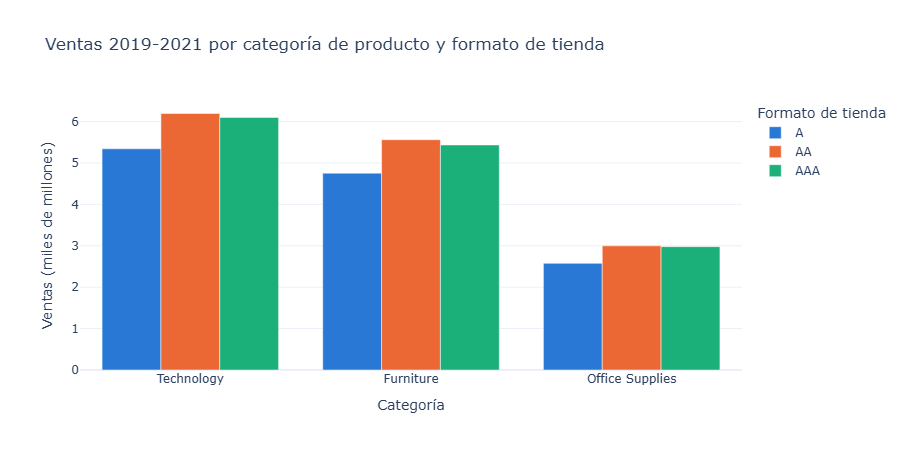

formato  tiendas
      A       60
     AA       71
    AAA       69


formato,A,AA,AAA
categoria,,,
Furniture,4754255695,5561721330,5434430401
Office Supplies,2576169961,2998166001,2979432012
Technology,5341913226,6194830318,6100039881


In [27]:
por_categoria_formato = practica.ventas_por(con, ["categoria", "formato"])
por_categoria_formato["ventas_mm"] = por_categoria_formato["ventas_total"] / 1e9

fig = px.bar(
    por_categoria_formato.sort_values(["formato", "ventas_mm"], ascending=[True, False]),
    x="categoria", y="ventas_mm", color="formato", barmode="group",
    category_orders={"formato": ["A", "AA", "AAA"]},
    color_discrete_sequence=["#2a78d6", "#eb6834", "#1baf7a"],
    labels={"categoria": "Categoría", "ventas_mm": "Ventas (miles de millones)", "formato": "Formato de tienda"},
    title="Ventas 2019-2021 por categoría de producto y formato de tienda",
    template="plotly_white",
)
fig.show()
print(con.sql("SELECT formato, count(*) AS tiendas FROM tiendas GROUP BY formato ORDER BY formato").df().to_string(index=False))
por_categoria_formato.pivot(index="categoria", columns="formato", values="ventas_total")

Technology es la categoría que más vende en los tres formatos, y en cada categoría los formatos `AA` y `AAA` superan al `A`, que también es el formato con menos tiendas.

## 7. Errores frecuentes

**Unir con una dimensión de clave repetida (*fan-out*).** Ya vimos en la sección 3 que la hoja cruda `t_store` infla el total sin avisar. En pandas, `merge` puede comprobar la cardinalidad con `validate`, y falla en lugar de duplicar filas:

In [28]:
ventas_tienda_17 = con.sql("SELECT * FROM ventas WHERE id_tienda = 17").df()
try:
    ventas_tienda_17.merge(t_store, left_on="id_tienda", right_on="ID_Store", validate="many_to_one")
except pd.errors.MergeError as error:
    print("MergeError:", str(error).splitlines()[0])

MergeError: Merge keys are not unique in right dataset; not a many-to-one merge


En SQL no existe ese seguro: hay que comprobar la clave antes (con `validar_modelo` o con `count(*)` frente a `count(DISTINCT ...)`).

**Unir por columnas de tipos distintos.** Si la clave de una dimensión quedó como texto, pandas se niega a unirla con una clave entera:

In [29]:
productos_texto = con.sql("SELECT * FROM productos").df().astype({"id_producto": str})
muestra = con.sql("SELECT * FROM ventas LIMIT 1000").df()
try:
    muestra.merge(productos_texto, on="id_producto")
except ValueError as error:
    print("ValueError:", str(error).splitlines()[0])

ValueError: You are trying to merge on int16 and object columns for key 'id_producto'. If you wish to proceed you should use pd.concat


DuckDB, en cambio, intenta convertir el texto en número para comparar. Funciona si el texto es un número limpio (incluso con ceros a la izquierda), y falla en cuanto aparece otra cosa:

In [30]:
for descripcion, expresion in [
    ("'1', '2', ...", "CAST(id_producto AS VARCHAR)"),
    ("'0001', '0002', ...", "lpad(CAST(id_producto AS VARCHAR), 4, '0')"),
    ("'ID-1', 'ID-2', ...", "'ID-' || id_producto"),
]:
    try:
        n = con.execute(f"""
            SELECT count(*)
            FROM ventas v
            JOIN (SELECT {expresion} AS id_producto FROM productos) p ON v.id_producto = p.id_producto
        """).fetchone()[0]
        print(f"{descripcion:22} -> {miles(n)} filas unidas")
    except duckdb.ConversionException as error:
        print(f"{descripcion:22} -> ConversionException: {str(error).splitlines()[0]}")

'1', '2', ...          -> 1 499 000 filas unidas
'0001', '0002', ...    -> 1 499 000 filas unidas
'ID-1', 'ID-2', ...    -> ConversionException: Conversion Error: Could not convert string 'ID-1' to INT16 when casting from source column id_producto


Que una unión entre texto y número "funcione" no la hace segura: la conversión depende del contenido y puede romperse con el próximo extracto. Las claves se dejan con el mismo tipo entero desde la preparación (Módulo 44).

**Unir por la columna equivocada.** `id_cliente` e `id_producto` son enteros pequeños cuyos rangos se solapan, así que unir los productos por el cliente no da ningún error. Peor aún: el total cuadra.

In [31]:
correcta = con.sql("""
    SELECT p.categoria, CAST(sum(v.importe) AS BIGINT) AS ventas
    FROM ventas v JOIN productos p ON v.id_producto = p.id_producto
    GROUP BY p.categoria
""").df()
equivocada = con.sql("""
    SELECT p.categoria, CAST(sum(v.importe) AS BIGINT) AS ventas_union_equivocada
    FROM ventas v JOIN productos p ON v.id_cliente = p.id_producto
    GROUP BY p.categoria
""").df()
comparacion = correcta.merge(equivocada, on="categoria").sort_values("ventas", ascending=False)
print("Totales:", miles(comparacion["ventas"].sum()), "y", miles(comparacion["ventas_union_equivocada"].sum()))
comparacion

Totales: 41 940 958 825 y 41 940 958 825


,categoria,ventas,ventas_union_equivocada
1,Technology,17636783425,18704612917
0,Furniture,15750407426,15112822318
2,Office Supplies,8553767974,8123523590


El total es idéntico porque cada venta encontró *alguna* fila de productos, pero el reparto por categoría es falso. Comprobar solo el total no basta: hay que revisar que cada `JOIN` use la clave de la relación, y usar `USING (id_producto)` cuando las columnas se llaman igual ayuda a no equivocarse.

**Agrupar por una columna descriptiva que no es única.** La clave de `tiendas` es única, pero el nombre no: dos tiendas distintas se llaman igual.

In [32]:
print(con.execute("SELECT count(*), count(DISTINCT tienda) FROM tiendas").fetchone())
con.sql("""
    SELECT id_tienda, tienda, direccion, formato
    FROM tiendas
    WHERE tienda IN (SELECT tienda FROM tiendas GROUP BY tienda HAVING count(*) > 1)
""").df()

(200, 199)


,id_tienda,tienda,direccion,formato
0,40,Schumm Inc,2815 Buell Court,AAA
1,197,Schumm Inc,0 Killdeer Circle,A


Si se agrupa solo por `tienda`, las ventas de las dos se suman en una sola barra, que puede acabar encabezando un ranking:

In [33]:
solo_nombre = con.sql("""
    SELECT t.tienda, CAST(sum(v.importe) AS BIGINT) AS ventas
    FROM ventas v JOIN productos p USING (id_producto) JOIN tiendas t USING (id_tienda)
    WHERE p.categoria = 'Furniture'
    GROUP BY t.tienda
    ORDER BY ventas DESC
    LIMIT 3
""").df()
con_clave = con.sql("""
    SELECT t.id_tienda, t.tienda, CAST(sum(v.importe) AS BIGINT) AS ventas
    FROM ventas v JOIN productos p USING (id_producto) JOIN tiendas t USING (id_tienda)
    WHERE p.categoria = 'Furniture'
    GROUP BY t.id_tienda, t.tienda
    ORDER BY ventas DESC
    LIMIT 3
""").df()
print(solo_nombre, end="\n\n")
print(con_clave)

         tienda     ventas
0    Schumm Inc  158647738
1  Lesch-Wunsch   86926256
2   Gerhold LLC   85572198

   id_tienda          tienda    ventas
0        112    Lesch-Wunsch  86926256
1        190     Gerhold LLC  85572198
2         91  Hansen-Bradtke  85039869


Para los rankings de entidades se agrupa por la clave **y** el nombre (la clave garantiza una fila por tienda; el nombre es lo que se muestra), o se agrega un dato que desambigüe, como el formato o la dirección.

**`INNER JOIN` frente a `LEFT JOIN` con huérfanas.** El modelo no tiene huérfanas, así que vamos a fabricarlas: una dimensión de países a la que le falta `US`.

In [34]:
con.execute("CREATE OR REPLACE VIEW paises_incompleto AS SELECT * FROM paises WHERE pais <> 'US'")
con.sql("""
    SELECT 'INNER JOIN' AS union_, count(*) AS filas, CAST(sum(v.importe) AS BIGINT) AS ventas,
           count(*) FILTER (WHERE p.pais IS NULL) AS sin_pais
    FROM ventas v INNER JOIN paises_incompleto p USING (id_pais)
    UNION ALL
    SELECT 'LEFT JOIN', count(*), CAST(sum(v.importe) AS BIGINT), count(*) FILTER (WHERE p.pais IS NULL)
    FROM ventas v LEFT JOIN paises_incompleto p USING (id_pais)
""").df()

,union_,filas,ventas,sin_pais
0,INNER JOIN,1348571,36915652874,0
1,LEFT JOIN,1499000,41940958825,150429


Con `INNER JOIN` las ventas de `US` desaparecen y el total baja sin aviso; con `LEFT JOIN` se conservan, con el país vacío (lo que en una herramienta de BI se ve como una categoría "(En blanco)"). La vista `ventas_detalle` usa `INNER JOIN`, y es correcto **solo porque** `validar_modelo` confirma que no hay huérfanas. Si las hubiera, la solución es completar la dimensión, no cambiar el tipo de unión.

**Olvidar filtrar desde la dimensión.** Con `LEFT JOIN`, una condición sobre la dimensión escrita en el `ON` no filtra los hechos: solo decide con qué filas se empareja cada venta. Las ventas que no cumplen siguen ahí, con la categoría vacía:

In [35]:
en_on, en_where = con.execute("""
    SELECT
        (SELECT sum(v.importe) FROM ventas v
         LEFT JOIN productos p ON v.id_producto = p.id_producto AND p.categoria = 'Furniture'),
        (SELECT sum(v.importe) FROM ventas v
         JOIN productos p ON v.id_producto = p.id_producto
         WHERE p.categoria = 'Furniture')
""").fetchone()
print("Condición en el ON del LEFT JOIN:", miles(en_on), "<- el total de todas las ventas")
print("Condición en el WHERE:           ", miles(en_where), "<- solo muebles")

Condición en el ON del LEFT JOIN: 41 940 958 825 <- el total de todas las ventas
Condición en el WHERE:            15 750 407 426 <- solo muebles


El filtro de una dimensión va en el `WHERE` (o en un `INNER JOIN`). Otra variante del mismo error es filtrar por el número de la clave (`WHERE id_pais = 2`) en lugar de por la columna descriptiva (`WHERE pais = 'CANADA'`): funciona, pero nadie sabe qué país es el 2 y la consulta se rompe si cambian las claves.

## 8. Ejercicio

Una cadena de librerías entrega estas tablas (la celda siguiente las genera con datos **simulados**):

| Tabla | Columnas |
| --- | --- |
| `pedidos` | `id_pedido`, `fecha_pedido`, `fecha_entrega`, `id_libro`, `id_sucursal`, `unidades`, `importe` |
| `libros` | `id_libro`, `titulo`, `id_genero`, `precio` |
| `generos` | `id_genero`, `genero` |
| `sucursales` | `id_sucursal`, `ciudad`, `region`, `direccion`, `vigente_desde` (dos sucursales aparecen dos veces por un cambio de dirección) |
| `calendario` | `fecha`, `anio`, `trimestre`, `mes`, `nombre_mes`, `anio_mes` |

In [36]:
import numpy as np

rng = np.random.default_rng(45)
generos = pd.DataFrame({"id_genero": range(1, 6), "genero": ["Novela", "Ensayo", "Poesía", "Infantil", "Historia"]})
libros = pd.DataFrame({
    "id_libro": range(1, 41),
    "titulo": [f"Libro {i:02d}" for i in range(1, 41)],
    "id_genero": rng.integers(1, 6, 40),
    "precio": rng.integers(8, 40, 40) * 10,
})
sucursales = pd.DataFrame({
    "id_sucursal": [1, 2, 2, 3, 4, 5, 5, 6],
    "ciudad": ["Lima", "Bogotá", "Bogotá", "Quito", "Santiago", "Ciudad de México", "Ciudad de México", "Montevideo"],
    "region": ["Andina", "Andina", "Andina", "Andina", "Sur", "Norte", "Norte", "Sur"],
    "direccion": ["Av. Arequipa 120", "Calle 72 #10-15", "Carrera 7 #45-20", "Av. Amazonas 300",
                  "Providencia 1500", "Insurgentes 800", "Reforma 250", "18 de Julio 900"],
    "vigente_desde": pd.to_datetime(["2020-01-01", "2019-03-01", "2024-06-01", "2021-05-01",
                                     "2018-09-01", "2017-02-01", "2024-03-15", "2022-11-01"]),
})
n = 3000
fecha_pedido = pd.Timestamp("2024-01-01") + pd.to_timedelta(rng.integers(0, 366, n), unit="D")
pedidos = pd.DataFrame({
    "id_pedido": range(1, n + 1),
    "fecha_pedido": fecha_pedido,
    "fecha_entrega": fecha_pedido + pd.to_timedelta(rng.integers(1, 11, n), unit="D"),
    "id_libro": rng.integers(1, 41, n),
    "id_sucursal": rng.integers(1, 7, n),
    "unidades": rng.integers(1, 6, n),
})
pedidos["importe"] = pedidos["unidades"] * pedidos["id_libro"].map(libros.set_index("id_libro")["precio"])
calendario = practica.calendario("2024-01-01", "2025-12-31")

lib = duckdb.connect()
for nombre, tabla in {"pedidos": pedidos, "libros": libros, "generos": generos,
                      "sucursales": sucursales, "calendario": calendario}.items():
    lib.register(nombre, tabla)
lib.sql("SHOW TABLES").df()

,name
0,calendario
1,generos
2,libros
3,pedidos
4,sucursales


1. Clasifica cada tabla como hechos o dimensión.
2. El modelo es un copo de nieve. Conviértelo en estrella.
3. ¿Qué problema impide usar `sucursales` como dimensión? Demuéstralo con un `JOIN` y resuélvelo.
4. Construye la tabla de relaciones del modelo estrella, con su cardinalidad, su dirección de filtro y si es activa.
5. Calcula el importe por mes de pedido y por mes de entrega con el mismo calendario.
6. Crea una vista `pedidos_detalle` solo con las columnas que debería ver quien construya un dashboard.

### Solución

**1 y 2.** `pedidos` es la tabla de hechos (una fila por pedido, con medidas aditivas `unidades` e `importe`); las demás son dimensiones. `generos` cuelga de `libros`, no de los hechos: es un copo de nieve. Se aplana uniendo `generos` dentro de `libros`:

In [37]:
for tabla in ["pedidos", "libros", "generos", "sucursales", "calendario"]:
    print(f"{tabla:11}", lib.execute(f"SELECT count(*) FROM {tabla}").fetchone()[0], "filas")

lib.execute("""
    CREATE OR REPLACE TABLE libros_plano AS
    SELECT l.id_libro, l.titulo, g.genero, l.precio
    FROM libros l
    JOIN generos g USING (id_genero)
""")
lib.sql("SELECT * FROM libros_plano ORDER BY id_libro LIMIT 3").df()

pedidos     3000 filas
libros      40 filas
generos     5 filas
sucursales  8 filas
calendario  731 filas


,id_libro,titulo,genero,precio
0,1,Libro 01,Historia,210
1,2,Libro 02,Poesía,90
2,3,Libro 03,Infantil,170


**3.** `id_sucursal` no es única: hay 8 filas para 6 sucursales, y el `JOIN` duplica los pedidos de las sucursales 2 y 5. Se resuelve dejando la dirección vigente (la de `vigente_desde` más reciente) con `QUALIFY`, que filtra por el resultado de una función de ventana:

In [38]:
print(lib.execute("SELECT count(*), count(DISTINCT id_sucursal) FROM sucursales").fetchone())
print("Pedidos:", lib.execute("SELECT count(*) FROM pedidos").fetchone()[0],
      "| tras unir con sucursales:", lib.execute("SELECT count(*) FROM pedidos JOIN sucursales USING (id_sucursal)").fetchone()[0])

lib.execute("""
    CREATE OR REPLACE TABLE sucursales_dim AS
    SELECT id_sucursal, ciudad, region, direccion
    FROM sucursales
    QUALIFY row_number() OVER (PARTITION BY id_sucursal ORDER BY vigente_desde DESC) = 1
""")
lib.sql("SELECT * FROM sucursales_dim ORDER BY id_sucursal").df()

(8, 6)
Pedidos: 3000 | tras unir con sucursales: 4026


,id_sucursal,ciudad,region,direccion
0,1,Lima,Andina,Av. Arequipa 120
1,2,Bogotá,Andina,Carrera 7 #45-20
2,3,Quito,Andina,Av. Amazonas 300
3,4,Santiago,Sur,Providencia 1500
4,5,Ciudad de México,Norte,Reforma 250
5,6,Montevideo,Sur,18 de Julio 900


**4.** Con la estrella ya construida, cada relación se comprueba igual que `validar_modelo`. La fecha de entrega es una segunda relación con el calendario; en SQL no hay que marcarla como inactiva, pero conviene documentarla así: por defecto se une por `fecha_pedido`, y solo las consultas que lo piden usan `fecha_entrega`.

In [39]:
relaciones_lib = [
    ("id_libro", "libros_plano", "id_libro", True),
    ("id_sucursal", "sucursales_dim", "id_sucursal", True),
    ("fecha_pedido", "calendario", "fecha", True),
    ("fecha_entrega", "calendario", "fecha", False),
]
filas = []
for columna, dimension, clave, activa in relaciones_lib:
    n_dim, d_dim = lib.execute(f"SELECT count(*), count(DISTINCT {clave}) FROM {dimension}").fetchone()
    huerfanas = lib.execute(
        f"SELECT count(*) FROM pedidos p ANTI JOIN {dimension} d ON p.{columna} = d.{clave}"
    ).fetchone()[0]
    filas.append({
        "desde": f"pedidos[{columna}]", "hacia": f"{dimension}[{clave}]",
        "cardinalidad": "*:1" if n_dim == d_dim else "*:*",
        "direccion_filtro": f"{dimension} -> pedidos",
        "activa": activa, "huerfanas": huerfanas,
    })
pd.DataFrame(filas)

,desde,hacia,cardinalidad,direccion_filtro,activa,huerfanas
0,pedidos[id_libro],libros_plano[id_libro],*:1,libros_plano -> pedidos,True,0
1,pedidos[id_sucursal],sucursales_dim[id_sucursal],*:1,sucursales_dim -> pedidos,True,0
2,pedidos[fecha_pedido],calendario[fecha],*:1,calendario -> pedidos,True,0
3,pedidos[fecha_entrega],calendario[fecha],*:1,calendario -> pedidos,False,0


Las cuatro relaciones son varios a uno y sin huérfanas: el calendario cubre 2024 y 2025, así que también las entregas de enero de 2025.

**5.** El mismo calendario, unido por cada fecha:

In [40]:
importe_mes = lib.sql("""
    WITH por_pedido AS (
        SELECT c.anio_mes, CAST(sum(p.importe) AS BIGINT) AS importe_por_pedido
        FROM pedidos p JOIN calendario c ON c.fecha = p.fecha_pedido
        GROUP BY c.anio_mes
    ),
    por_entrega AS (
        SELECT c.anio_mes, CAST(sum(p.importe) AS BIGINT) AS importe_por_entrega
        FROM pedidos p JOIN calendario c ON c.fecha = p.fecha_entrega
        GROUP BY c.anio_mes
    )
    SELECT * FROM por_entrega LEFT JOIN por_pedido USING (anio_mes)
    ORDER BY anio_mes
""").df()
print("Totales:", miles(importe_mes["importe_por_pedido"].sum()), "y", miles(importe_mes["importe_por_entrega"].sum()))
pd.concat([importe_mes.head(2), importe_mes.tail(2)])

Totales: 1 855 960 y 1 855 960


,anio_mes,importe_por_entrega,importe_por_pedido
0,2024-01,145100,178640
1,2024-02,177150,171410
11,2024-12,142150,144520
12,2025-01,25880,<NA>


Enero de 2025 solo tiene importe por entrega, porque ahí caen los pedidos de finales de diciembre; los totales coinciden porque el calendario cubre todas las fechas.

**6.** La vista expone las columnas descriptivas y las medidas, y deja fuera las claves técnicas (`id_pedido`, `id_libro`, `id_sucursal`, `id_genero`) y las fechas crudas, que se consultan a través del calendario:

In [41]:
lib.execute("""
    CREATE OR REPLACE VIEW pedidos_detalle AS
    SELECT c.anio, c.mes, c.anio_mes, l.titulo, l.genero, s.ciudad, s.region, p.unidades, p.importe
    FROM pedidos p
    JOIN libros_plano l USING (id_libro)
    JOIN sucursales_dim s USING (id_sucursal)
    JOIN calendario c ON c.fecha = p.fecha_pedido
""")
lib.sql("""
    SELECT genero, CAST(sum(unidades) AS BIGINT) AS unidades, CAST(sum(importe) AS BIGINT) AS importe
    FROM pedidos_detalle
    GROUP BY genero
    ORDER BY importe DESC
""").df()

,genero,unidades,importe
0,Poesía,3643,813670
1,Infantil,2609,537700
2,Historia,1915,359610
3,Ensayo,521,85200
4,Novela,427,59780


In [42]:
total_pedidos, total_vista = lib.execute(
    "SELECT (SELECT sum(importe) FROM pedidos), (SELECT sum(importe) FROM pedidos_detalle)"
).fetchone()
print("Importe en pedidos:", miles(total_pedidos), "| en pedidos_detalle:", miles(total_vista))

Importe en pedidos: 1 855 960 | en pedidos_detalle: 1 855 960


El total de la vista coincide con el de la tabla de hechos: la estrella no pierde ni duplica pedidos.

## Resumen

- La tabla de hechos guarda eventos medibles con una granularidad definida; las dimensiones los describen. Las consultas agrupan y filtran por dimensiones y agregan las medidas aditivas de los hechos.
- El esquema estrella, con cada dimensión unida directamente a los hechos, es el diseño preferido en BI: un salto por filtro y consultas más simples. Un copo de nieve se aplana al preparar los datos.
- La relación habitual es uno a varios, y exige una clave única y del mismo tipo en la dimensión. `count(*)` frente a `count(DISTINCT ...)` y `validar_modelo` lo comprueban; una clave repetida infla los totales sin avisar (*fan-out*).
- El filtro va de la dimensión a los hechos (`JOIN` + `WHERE`). El camino inverso es un semi-join (`EXISTS`, `SEMI JOIN`) y conviene escribirlo como una medida explícita.
- En SQL cada consulta elige por qué columna unir: eso sustituye a las relaciones inactivas, y una dimensión de fechas puede cumplir varios roles si cubre todas sus fechas.
- Las medidas viven como funciones en `ventas.py`, con filtros sobre columnas descriptivas y sin exponer las claves técnicas.

En el **Módulo 46** se construye el primer dashboard sobre este modelo con Plotly y Streamlit, y se resalta la información importante con formato condicional.